In [65]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
from itertools import product

plt.rcParams.update({
  "font.size": 8,
  "axes.titlesize": 8,
  "axes.labelsize": 8,
  "xtick.labelsize": 8,
  "ytick.labelsize": 8,
  "legend.fontsize": 8
})

In [66]:
cell_ids = np.arange(0, 20)

stimulations = {
  "noTI_0.1": "No\ntTIS",
  "1000_5_0.5_0.1": "50%\ntTIS",
  "1000_5_0.9_0.1": "90%\ntTIS"
}

frequencies = np.arange(1, 26)

In [67]:
# Somatic firing frequency
somatic_firing = list()
for cell_id, stimulation, frequency in product(cell_ids, stimulations.keys(), frequencies):
  filename = f"output/temporal-interference-1/{cell_id}/random_poisson/{frequency}/{stimulation}/spike_frequency.csv"
  n_spikes = len(pd.read_csv(filename, index_col = 0))
  spike_freq = n_spikes / 10

  somatic_firing.append(
    pd.DataFrame({
      "Stimulation": [stimulations[ stimulation ]],
      "Somatic": [spike_freq],
      "Poisson": frequency,
      "Cell": cell_id
    })
  )

somatic_firing = pd.concat(somatic_firing, ignore_index = True)

In [68]:
def p_to_stars(p):
  if p < 1e-4:
    return "****"
  elif p < 1e-3:
    return "***"
  elif p < 1e-2:
    return "**"
  elif p < 0.05:
    return "*"
  else:
    return "ns"

In [69]:
def plot_violin_frequency(data, frequency, ax):
  dt = data[ somatic_firing.Poisson == frequency ][["Stimulation", "Somatic"]]
  grouped = list(dt.groupby("Stimulation"))
  labels = [name for name, _ in grouped]
  groups = [g["Somatic"].values for _, g in grouped]

  label_to_group = dict(zip(labels, groups))
  labels = stimulations.values()
  groups = [label_to_group[l] for l in labels]

  violin = ax.violinplot(
    groups,
    showmeans = False,
    showmedians = False,
    showextrema = False
  )

  # style violins
  for body in violin["bodies"]:
    body.set_facecolor("white")
    body.set_edgecolor("black")
    body.set_linewidth(0.8)
    body.set_alpha(1)

  ax.set_xticks(range(1, len(labels) + 1))
  ax.set_xticklabels(labels)

  ax.xaxis.set_ticks_position("bottom")
  ax.yaxis.set_ticks_position("left")
  ax.tick_params(axis="x", bottom=True, top=False, length=4)
  ax.tick_params(axis="y", left=True, right=False, length=4)

  ax.spines["top"].set_visible(False)
  ax.spines["right"].set_visible(False)
  ax.grid(alpha = 0.25)

  ax.set_ylabel("Frequency, Hz")

  # stats vs No TI
  ref_idx = 0

  y_max = max([g.max() for g in groups])
  y_offset = 0.05 * y_max

  for i in range(len(groups)):
    if i == ref_idx:
      continue

    stat, p_val = stats.mannwhitneyu(groups[ref_idx], groups[i], alternative="two-sided")
    stars = p_to_stars(p_val)

    x = i + 1
    y = groups[i].max() + y_offset

    ax.text(x, y, stars, ha="center", va="bottom")
  
  ax.set_title(f"{frequency} Hz")

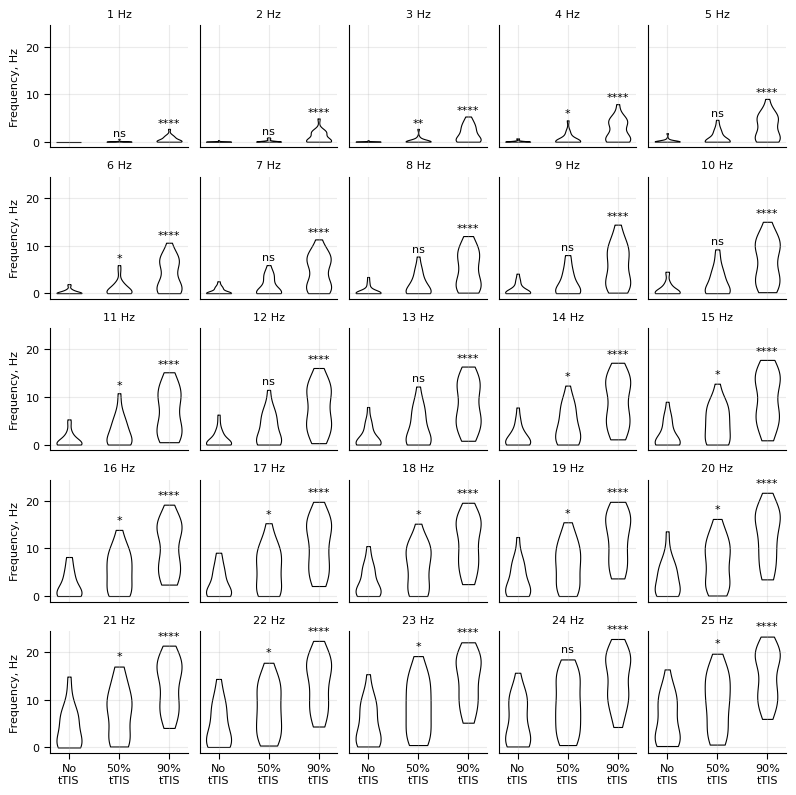

In [73]:
fig, axs = plt.subplots(nrows = 5, ncols = 5, sharey = True, sharex = True, figsize = (8, 8))

for ax, frequency in zip(axs.flatten(), frequencies):
  plot_violin_frequency(somatic_firing, frequency, ax)

for ax_row in axs:
  for ax in ax_row[1:]:
      ax.set_ylabel("")
      ax.tick_params(left = False, labelleft = False)

for ax_col in axs[:-1, :].flat:
    ax_col.set_xlabel("")
    ax_col.tick_params(bottom = False, labelbottom = False)

plt.tight_layout()
plt.show()